In [272]:
import numpy as np
from scipy import io
import matplotlib.pyplot as plt
from src.utils import setup_plot_style, import_vars_from_matlab
from path_setup import setup_project_path
from src.ActivityPipelines import ActivityLoader
from src.DistanceProject import DistanceAnalysis, create_new_result_dir
from src.DistancePlots import plot_repeats, plot_trials, plot_raw_traces, plot_trials_ordered, plot_reliability_distribution, plot_trials_ordered_2, plot_boxplot, plot_RF_vs_modulation
import os
from scipy.stats import f_oneway

colors = setup_plot_style()

%load_ext autoreload
%autoreload 2

data_dir = r'D:/data-distance-coding-project/processed-data'
session = r'250228_SAM032'

session_path = os.path.join(data_dir, session)
results_path = create_new_result_dir(session_path, r'results')
stimulus_path = os.path.join(session_path, r'stimulus')
activity_path = os.path.join(session_path, r'suite2p\plane0')

# check files inside stimulus_path
filelist = [file for file in os.listdir(stimulus_path) if file.endswith(("_stimulus.mat"))]
if len(filelist) == 0:
    # raise error
    raise Exception('No stimulus file found')
elif len(filelist) > 1:
    raise Exception('More than one stimulus file found')
else:
    print('Stimulus file found')

container = io.loadmat(stimulus_path + '/' + str(filelist[0]))

D = ActivityLoader(session_path)
# D.dFF = (D.dFF - np.mean(D.dFF, axis=1)[:, np.newaxis]) / np.std(D.dFF, axis=1)[:, np.newaxis]
frames_time = D.frames_time

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Directory results already exists
Stimulus file found


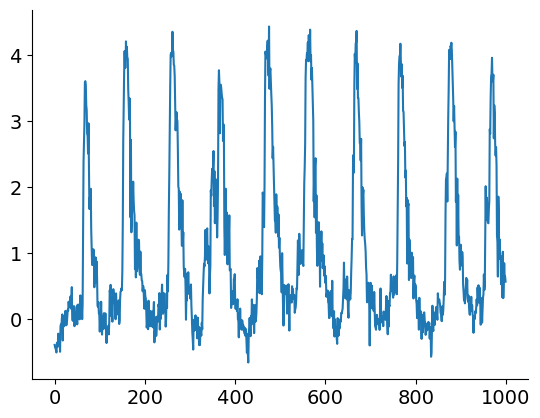

In [204]:
#plt.figure()
plt.plot(D.dFF[315][:1000].T)
plt.show()

In [205]:
time = []
stepper_pos = []
servo_id = []
mini_servo_active = []
trial_sequence = []
history_sequence = []
trial_start_time = []
trial_end_time = []

field_names = import_vars_from_matlab(container, 'stim', locals())

stepper_pos_interp = np.interp(D.frames_time, time, stepper_pos)
on_time_interp = np.round(np.interp(D.frames_time, time, mini_servo_active)).astype(bool)
identity_interp = np.round(np.interp(D.frames_time, time, servo_id)).astype(int)

In [220]:
def create_monocular_sequence(trial_sequence_length):
    # Create array of the same length as trial_sequence
    monocular_sequence = np.zeros(trial_sequence_length, dtype=bool)

    # Calculate quarter points
    quarter = trial_sequence_length // 4

    # Set first quarter to True
    monocular_sequence[:quarter] = True

    # Set third quarter to True
    monocular_sequence[2*quarter:3*quarter] = True

    return monocular_sequence

def find_suite2p_to_cell(suite2p_cell_id):
    return np.where(D.suite2p_id == suite2p_cell_id)[0]

def find_cell_to_suite2p(cell_id):
    return D.suite2p_id[cell_id]


In [209]:
monocular_sequence = create_monocular_sequence(len(trial_sequence))

In [210]:
def get_trial_frames(repeat):

    trial_start = 1000*trial_start_time[repeat]
    trial_end = 1000*trial_end_time[repeat]

    return (frames_time > trial_start) & (frames_time < trial_end)

def get_on_frames(repeat):

    on_start = 1000*trial_start_time[repeat]
    on_end = 1000*trial_end_time[repeat]

    return (frames_time > on_start) & (frames_time < on_end) & on_time_interp

def get_on_times(repeat):

    on_frames = get_on_frames(repeat)

    return frames_time[on_frames][0], frames_time[on_frames][-1]

def get_on_trace(cell, repeat):

    on_frames = get_on_frames(repeat)
    trace = D.dFF[cell, on_frames]
    trace = trace[:25]

    return trace

def get_all_traces(cell, distance=None, mean_trace=False, block=None):

    all_traces = []

    if block is None:
        # make a true vector of size trial sequence
        block = np.ones(len(trial_sequence), dtype=bool)[:-1]
    elif block == 'one eye':
        block = monocular_sequence
    elif block == 'two eyes':
        block = ~monocular_sequence

    repeat_number = 0
    for repeat in range(len(trial_sequence[:-1])):

        if not block[repeat]:
            continue

        if distance is not None:
            if distance != trial_sequence[repeat]:
                continue

            on_trace = get_on_trace(cell, repeat)
            all_traces.append(on_trace.T)
            repeat_number += 1

        else:
            on_trace = get_on_trace(cell, repeat)
            all_traces.append(on_trace.T)
            repeat_number += 1

    if mean_trace:
        return np.mean(all_traces, axis=0), np.std(all_traces, axis=0)/np.sqrt(repeat_number)
    else:
        return np.squeeze(np.array(all_traces))
    
def get_RF_value(cell, receptive_field=None, distance=None, block=None):
    """
    Extract the value at the receptive field position for a given cell.
    
    Parameters:
    -----------
    cell : int
        The cell ID to analyze.
    receptive_field : int, optional
        The index position of the receptive field. If None, it will be determined
        as the position of maximum response in the mean trace.
    distance : float, optional
        If provided, only trials with this distance value will be included.
    block : str or array-like, optional
        Specifies which trials to include. Can be 'one eye', 'two eyes', or a boolean array.
        
    Returns:
    --------
    rf_values : list
        List of receptive field values for each trial trace.
    """

    if receptive_field is None:
        traces_all_mean, _ = get_all_traces(cell, mean_trace=True)
        receptive_field = np.argmax(traces_all_mean)

    all_traces = get_all_traces(cell, distance=distance, block=block)
    rf_values = all_traces[:, receptive_field]

    return rf_values
   

In [281]:
cell = 315
fig_path = create_new_result_dir(results_path, r'cell_traces_10_repeats')

def plot_cell_stimulus_response(cell, fig_path=None, n_repeats=10):
    """
    Plot the stimulus response for a given cell.
    
    Parameters:
    -----------
    cell : int
        The cell ID to analyze.
    fig_path : str, optional
        Path to save the figure. If provided, the figure will be saved.
    n_repeats : int or list, optional
        Number of repeats to plot or range of repeats [start, end] to plot.
        Default is 10 (plots first 10 repeats).
    
    Returns:
    --------
    fig : matplotlib.figure.Figure
        The figure object.
    """
    fig = plt.figure(figsize=(14,4))

    # Handle both single number and range inputs for n_repeats
    if isinstance(n_repeats, (list, tuple)) and len(n_repeats) == 2:
        repeats = np.arange(n_repeats[0], n_repeats[1])
    else:
        repeats = np.arange(n_repeats)

    repeat_start = trial_start_time[repeats[0]]*1000
    repeat_end = trial_end_time[repeats[-1]]*1000

    repeats_frames = (frames_time > repeat_start) & (frames_time < repeat_end)

    ax = plt.gca()
    ax1 = ax.twinx()
    ax.plot(frames_time[repeats_frames], D.dFF[cell, repeats_frames].T)
    ax1.plot(frames_time[repeats_frames], stepper_pos_interp[repeats_frames]/30, lw=1, color='gray')

    for rep in repeats:
        trial_start, trial_end = get_on_times(rep)
        plt.axvspan(trial_start, trial_end, color=colors[trial_sequence[rep]], alpha=0.5)
        plt.axvspan(trial_start-2500, trial_end-2500, color='gray', alpha=0.5)
        plt.title('Cell ' + str(D.suite2p_id[cell]) + ' spikes')

    if fig_path is not None:
        plt.savefig(fig_path + '/cell_' + str(D.suite2p_id[cell]) + '.png')
        plt.close()
        
    return fig


Directory cell_traces_10_repeats already exists


In [320]:
def plot_condition_comparison(cell, fig_path=None):
    """
    Creates a plot comparing one eye vs two eyes conditions with colorplots and mean responses.
    
    Parameters:
    -----------
    cell : int
        The cell ID to analyze.
    fig_path : str, optional
        Path to save the figure.
        
    Returns:
    --------
    fig : matplotlib.figure.Figure
        The figure object.
    """
    fig = plt.figure(figsize=(14, 8))
    gs = fig.add_gridspec(4, 2, height_ratios=[2, 2, 2, 3])
    axes = np.array([[fig.add_subplot(gs[i, j]) for j in range(2)] for i in range(4)])
    
    distances = [1, 2, 3]
    conditions = ['one eye', 'two eyes']
    distance_labels = ['Near', 'Medium', 'Far']
    condition_titles = ['One Eye', 'Two Eyes']

    all_data = get_all_traces(cell, block=None)
    vmin, vmax = np.percentile(all_data, [1, 99])
    
    for col, condition in enumerate(conditions):
        axes[0, col].set_title(condition_titles[col], fontsize=16)

        for row, distance in enumerate(distances):
            ax = axes[row, col]
            traces = get_all_traces(cell, distance=distance, block=condition)
            im = ax.pcolor(traces, cmap='viridis', vmin=vmin, vmax=vmax)
            
            ax.set_xticklabels([])
            ax.set_xticks([])
            ax.set_ylabel("Trial #")
            
            mean_trace = np.mean(traces, axis=0)
            axes[3, col].plot(mean_trace, label=distance_labels[row], color=colors[distance])
    
    for col in range(2):
        axes[3, col].set_xlabel("Time (frames)")
        axes[3, col].set_ylabel("Mean dF/F")
        axes[3, col].set_title("Mean Response by Distance")
        axes[3, col].legend()
        axes[3, col].set_ylim(vmin, vmax)
    
    cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
    fig.colorbar(im, cax=cbar_ax, label='dF/F')
    
    fig.suptitle(f'Cell {D.suite2p_id[cell]} Responses', fontsize=24)
    plt.tight_layout(rect=[0, 0, 0.9, 0.95])
    
    if fig_path is not None:
        plt.savefig(fig_path + '/cell_' + str(D.suite2p_id[cell]) + '_condition_comparison.png')
        plt.close()
        
    return fig

def plot_cell_distance_response(cell, figure_path=None):
    """
    Plot RF values by distance, comparing one eye vs two eyes conditions.
    
    Parameters:
    -----------
    cell : int
        Cell index to analyze
    figure_path : str, optional
        Path to save the figure.
    """
    if figure_path is None:
        figure_path = create_new_result_dir(results_path, r'block_response')
    
    distances = [1, 2, 3]
    fig, axes = plt.subplots(1, 2, figsize=(8,5))
    fig.suptitle(f'RF Values by Distance - Cell {D.suite2p_id[cell]}', fontsize=16)

    one_eye_data = [get_RF_value(cell=cell, distance=d, block='one eye') for d in distances]
    two_eyes_data = [get_RF_value(cell=cell, distance=d, block='two eyes') for d in distances]

    all_data = np.concatenate(one_eye_data + two_eyes_data)
    y_min, y_max = np.min(all_data), np.max(all_data)
    y_range = y_max - y_min
    y_lims = [y_min - 0.1*y_range, y_max + 0.2*y_range]

    for ax, data, title in zip(axes, [one_eye_data, two_eyes_data], ['One Eye Trials', 'Two Eyes Trials']):
        bp = ax.boxplot(data, patch_artist=True, showfliers=False)
        for patch in bp['boxes']:
            patch.set_facecolor('none')
            
        for i, values in enumerate(data):
            x_jitter = np.random.normal(0, 0.05, size=len(values))
            ax.scatter(np.ones_like(values) * (i+1) + x_jitter, values,
                      color=colors[i+1], alpha=0.7, s=40, label=f"{distances[i]:.1f}")
        
        ax.set_title(title)
        ax.set_ylabel('RF Value')
        ax.set_xlabel('Distance')
        ax.set_xticks(range(1, len(distances) + 1))
        ax.set_xticklabels([f"{d:.1f}" for d in distances])
        ax.set_ylim(y_lims)
        
        p_value = f_oneway(*data).pvalue
        y_bar = max([max(d) for d in data]) + 0.1 * y_range
        ax.plot([1, 1, len(distances), len(distances)], [y_bar, y_bar+0.05*y_range, y_bar+0.05*y_range, y_bar], lw=1.5, color='k')
        ax.text(len(distances)/2, y_bar + 0.05*y_range, '*' if p_value < 0.05 else 'n.s.', ha='center', va='bottom')

    plt.tight_layout()
    
    if figure_path:
        plt.savefig(figure_path + '/cell_' + str(D.suite2p_id[cell]) + '_boxplot.png')
    
    return fig, axes

In [334]:
def plot_distance_response(cell, fig_path=None):
    """
    Creates a simplified plot with only mean responses and RF value boxplots.
    
    Parameters:
    -----------
    cell : int
        The cell ID to analyze.
    fig_path : str, optional
        Path to save the figure.
        
    Returns:
    --------
    fig, axes : Figure and axes objects
    """
    fig = plt.figure(figsize=(14, 8))
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.2])
    axes = np.array([[fig.add_subplot(gs[i, j]) for j in range(2)] for i in range(2)])
    
    distances = [1, 2, 3]
    conditions = ['one eye', 'two eyes']
    distance_labels = ['Near', 'Medium', 'Far']
    condition_titles = ['One Eye', 'Two Eyes']

    all_data = get_all_traces(cell, block=None)
    vmin, vmax = np.percentile(all_data, [1, 99])
    
    # Plot mean traces
    for col, condition in enumerate(conditions):
        axes[0, col].set_title(condition_titles[col], fontsize=16)
        
        for distance in distances:
            traces = get_all_traces(cell, distance=distance, block=condition)
            mean_trace = np.mean(traces, axis=0)
            axes[0, col].plot(mean_trace, label=distance_labels[distance-1], color=colors[distance], lw=2)
        # add title based on condition
        axes[0, col].set_title(condition_titles[col])
    
    for col in range(2):
        axes[0, col].set_xlabel("Time (frames)")
        axes[0, col].set_ylabel("Mean dF/F")
        axes[0, col].legend()
        axes[0, col].set_ylim(vmin, vmax)
    
    # Plot boxplots
    one_eye_data = [get_RF_value(cell=cell, distance=d, block='one eye') for d in distances]
    two_eyes_data = [get_RF_value(cell=cell, distance=d, block='two eyes') for d in distances]

    all_rf_data = np.concatenate(one_eye_data + two_eyes_data)
    y_min, y_max = np.min(all_rf_data), np.max(all_rf_data)
    y_range = y_max - y_min
    y_lims = [y_min - 0.1*y_range, y_max + 0.2*y_range]

    for col, (data, title) in enumerate(zip([one_eye_data, two_eyes_data], ['One Eye Trials', 'Two Eyes Trials'])):
        ax = axes[1, col]
        
        bp = ax.boxplot(data, patch_artist=True, showfliers=False)
        for patch in bp['boxes']:
            patch.set_facecolor('none')
            
        for i, values in enumerate(data):
            x_jitter = np.random.normal(0, 0.05, size=len(values))
            ax.scatter(np.ones_like(values) * (i+1) + x_jitter, values,
                      color=colors[i+1], alpha=0.7, s=40)
        
        ax.set_title(f"RF Values - {title}")
        ax.set_ylabel('RF Value')
        ax.set_xlabel('Distance')
        ax.set_xticks(range(1, len(distances) + 1))
        ax.set_xticklabels([f"{d:.1f}" for d in distances])
        ax.set_ylim(y_lims)
        
        p_value = f_oneway(*data).pvalue
        y_bar = max([max(d) for d in data]) + 0.1 * y_range
        ax.plot([1, 1, len(distances), len(distances)], [y_bar, y_bar+0.05*y_range, y_bar+0.05*y_range, y_bar], lw=1.5, color='k')
        ax.text(len(distances)/2, y_bar + 0.05*y_range, '*' if p_value < 0.05 else 'n.s.', ha='center', va='bottom')
    
    fig.suptitle(f'Cell {D.suite2p_id[cell]}', fontsize=24)
    plt.tight_layout()
    
    if fig_path is not None:
        plt.savefig(fig_path + '/cell_' + str(D.suite2p_id[cell]) + '_simplified_analysis.png')
        plt.close()
        
    return fig, axes

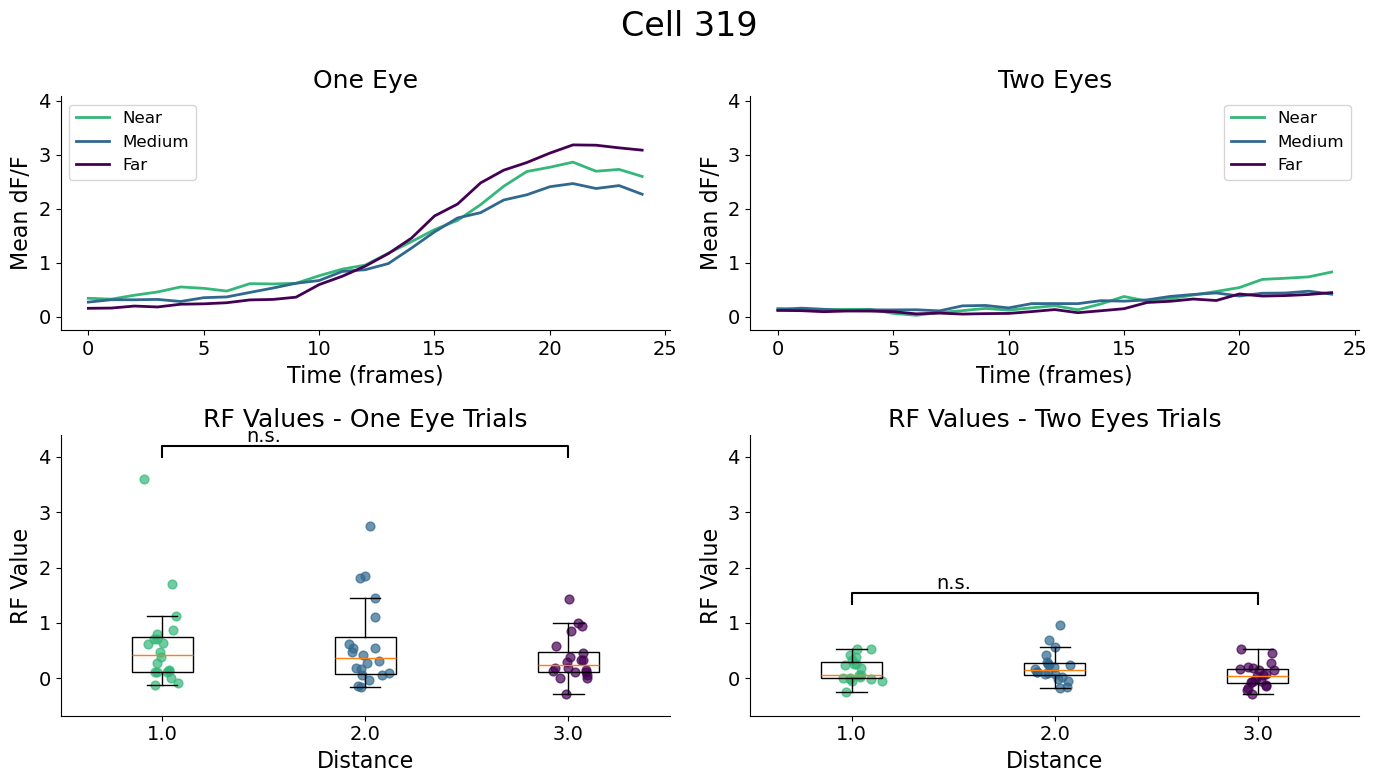

In [332]:
fig = plot_distance_response(315)

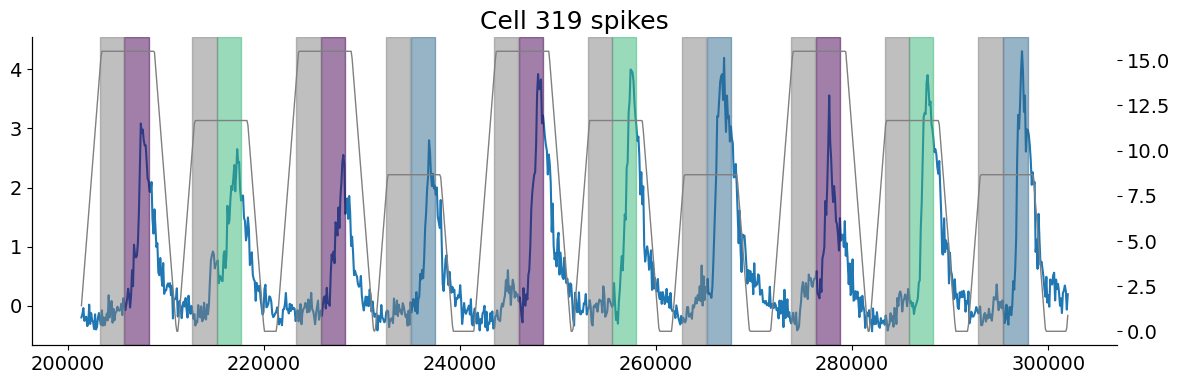

In [282]:
fig = plot_cell_stimulus_response(315, n_repeats=[20, 30])

First, see the cells that can be analyzed. I can set some metric as if they are significantly more active during on_times than during off_times

Found 355 responsive cells out of 563 total cells
Directory responsive_cells already exists
 Cell 562 of 563

IndexError: index 562 is out of bounds for axis 0 with size 562

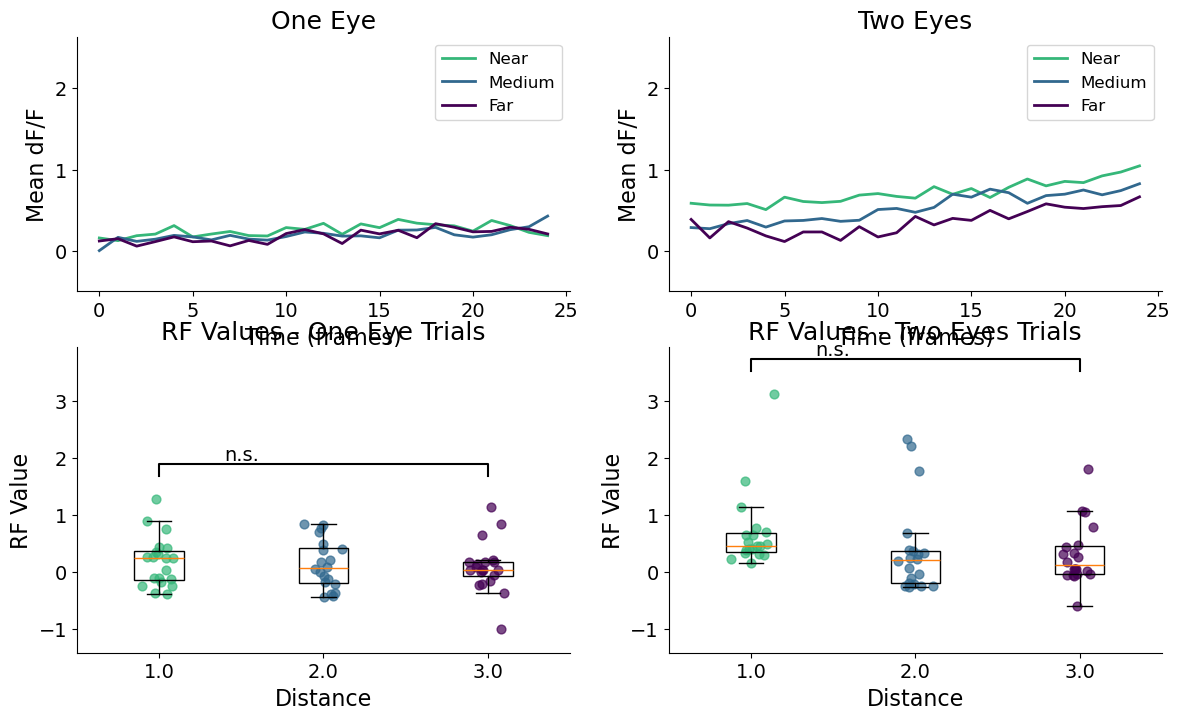

In [337]:
def is_cell_responsive(cell):
    """
    Determines if a cell is significantly more active during on times than off times.
    
    Args:
        cell: Cell index to analyze
        
    Returns:
        bool: True if cell is significantly more active during on times
    """
    # Z-score the dFF data for the cell
    z_scored = (D.dFF[cell] - np.mean(D.dFF[cell])) / np.std(D.dFF[cell])
    
    # Get on and off time activity
    on_activity = z_scored[on_time_interp]
    off_activity = z_scored[~on_time_interp]
    
    # Perform t-test
    _, p_value = ttest_ind(on_activity, off_activity)
    
    # Check if mean on activity is greater and p-value significant
    return (np.mean(on_activity) > np.mean(off_activity)) and (p_value < 0.05)

# Get responsive cells
responsive_cells = []
for cell in range(D.dFF.shape[0]):
    if is_cell_responsive(cell):
        responsive_cells.append(cell)
        
print(f"Found {len(responsive_cells)} responsive cells out of {D.dFF.shape[0]} total cells")

# make folder in results path
figure_path = create_new_result_dir(results_path, r'responsive_cells')

n_cells = D.dFF.shape[0]
for cell in responsive_cells:
    # update print line
    print('\r Cell ' + str(cell) + ' of ' + str(n_cells), end="")
    plot_distance_response(cell, fig_path=figure_path)

# Get unresponsive cells
unresponsive_cells = []
for cell in range(D.dFF.shape[0]):
    if not is_cell_responsive(cell):
        unresponsive_cells.append(cell)
        
print(f"Found {len(unresponsive_cells)} unresponsive cells out of {D.dFF.shape[0]} total cells")

# make folder in results path
figure_path = create_new_result_dir(results_path, r'unresponsive_cells')
n_cells = D.dFF.shape[0]
for cell in unresponsive_cells:
    plot_distance_response(cell, fig_path=figure_path)

In [318]:
from scipy.stats import f_oneway

def plot_cell_distance_response(cell, figure_path=None):
    """
    Plot RF values by distance for a given cell, comparing one eye vs two eyes conditions.
    
    Parameters:
    -----------
    cell : int
        Cell index to analyze
    figure_path : str, optional
        Path to save the figure. If None, figure won't be saved.
    """
    if figure_path is None:
        figure_path = create_new_result_dir(results_path, r'block_response')
    
    distances = [1, 2, 3]

    # Set up figure
    fig, axes = plt.subplots(1, 2, figsize=(8,5))
    fig.suptitle(f'RF Values by Distance - Cell {D.suite2p_id[cell]}', fontsize=16)

    # Get data for both conditions
    one_eye_data = [get_RF_value(cell=cell, distance=d, block='one eye') for d in distances]
    two_eyes_data = [get_RF_value(cell=cell, distance=d, block='two eyes') for d in distances]

    # Set y-axis limits
    all_data = np.concatenate(one_eye_data + two_eyes_data)
    y_min, y_max = np.min(all_data), np.max(all_data)
    y_range = y_max - y_min
    y_lims = [y_min - 0.1*y_range, y_max + 0.2*y_range]

    # Plot both conditions
    for ax, data, title in zip(axes, [one_eye_data, two_eyes_data], ['One Eye Trials', 'Two Eyes Trials']):
        # Create boxplot
        bp = ax.boxplot(data, patch_artist=True, showfliers=False)
        for patch in bp['boxes']:
            patch.set_facecolor('none')
            
        # Add scatter points with jitter
        for i, values in enumerate(data):
            x_jitter = np.random.normal(0, 0.05, size=len(values))
            ax.scatter(np.ones_like(values) * (i+1) + x_jitter, values,
                      color=colors[i+1], alpha=0.7, s=40, label=f"{distances[i]:.1f}")
        
        # Configure axis
        ax.set_title(title)
        ax.set_ylabel('RF Value')
        ax.set_xlabel('Distance')
        ax.set_xticks(range(1, len(distances) + 1))
        ax.set_xticklabels([f"{d:.1f}" for d in distances])
        ax.set_ylim(y_lims)
        
        # Add significance bar
        p_value = f_oneway(*data).pvalue
        y_bar = max([max(d) for d in data]) + 0.1 * y_range
        ax.plot([1, 1, len(distances), len(distances)], [y_bar, y_bar+0.05*y_range, y_bar+0.05*y_range, y_bar], lw=1.5, color='k')
        ax.text(len(distances)/2, y_bar + 0.05*y_range, '*' if p_value < 0.05 else 'n.s.', ha='center', va='bottom')

    plt.tight_layout()
    
    if figure_path:
        plt.savefig(figure_path + '/cell_' + str(D.suite2p_id[cell]) + '_boxplot.png')
    
    return fig, axes

Directory block_response already exists


(<Figure size 800x500 with 2 Axes>,
 array([<Axes: title={'center': 'One Eye Trials'}, xlabel='Distance', ylabel='RF Value'>,
        <Axes: title={'center': 'Two Eyes Trials'}, xlabel='Distance', ylabel='RF Value'>],
       dtype=object))

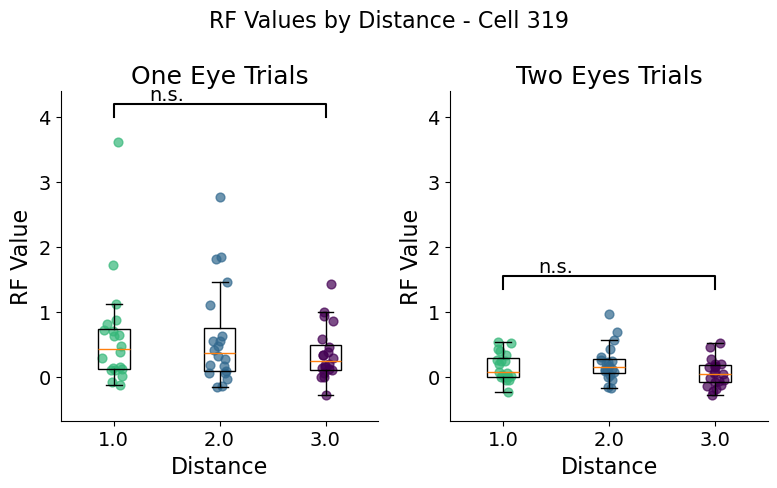

In [271]:
plot_cell_distance_response(315)

In [ ]:
# Compute p-values for each cell and block
n_cells = D.dFF.shape[0]
p_values = {}

for cell in range(n_cells):
    # Get cell ID
    cell_id = D.suite2p_id[cell]
    p_values[cell_id] = {}
    
    # Get data for both conditions
    one_eye_data = np.array([get_RF_value(cell=cell, distance=d, block='one eye') for d in distances])
    two_eyes_data = np.array([get_RF_value(cell=cell, distance=d, block='two eyes') for d in distances])

    # if the RF_value mean is less than 1, then cell can't be significant, but separetly for each condition
    if np.mean(one_eye_data.flatten()) < 1:
        p_values[cell_id]['one_eye'] = 1
    else:
        p_values[cell_id]['one_eye'] = f_oneway(*one_eye_data).pvalue
    if np.mean(two_eyes_data.flatten()) < 1:
        p_values[cell_id]['two_eyes'] = 1
    else:
        p_values[cell_id]['two_eyes'] = f_oneway(*two_eyes_data).pvalue
    continue

# Print cell with p-value < 0.05
for cell_id in p_values:
    if p_values[cell_id]['one_eye'] < 0.05:
        print(f"Cell {cell_id} has a significant difference in one eye trials")
    if p_values[cell_id]['two_eyes'] < 0.05:
        print(f"Cell {cell_id} has a significant difference in two eyes trials")



ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (3,) + inhomogeneous part.

In [186]:
# sum cells with p-value < 0.05 for each condition
one_eye_count = sum(1 for cell_id in p_values if p_values[cell_id]['one_eye'] < 0.05)
two_eyes_count = sum(1 for cell_id in p_values if p_values[cell_id]['two_eyes'] < 0.05)

print(f"Number of cells with significant difference in one eye trials: {one_eye_count}")
print(f"Number of cells with significant difference in two eyes trials: {two_eyes_count}")

Number of cells with significant difference in one eye trials: 29
Number of cells with significant difference in two eyes trials: 40


In [183]:
print(D.dFF.shape)

(563, 12099)


Directory all_traces already exists
 Cell 141 of 563

KeyboardInterrupt: 

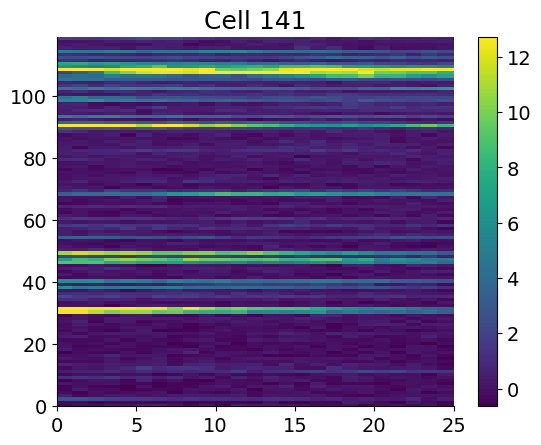

In [187]:
# make folder in results path
figure_path = create_new_result_dir(results_path, r'all_traces')

n_cells = D.dFF.shape[0]
for cell in range(n_cells):

    # update print line
    print('\r Cell ' + str(cell) + ' of ' + str(n_cells), end="")

    plt.figure()
    plt.title('Cell ' + str(D.suite2p_id[cell]))
    all_traces = get_all_traces(cell)

    vmin = np.percentile(all_traces, 1)
    vmax = np.percentile(all_traces, 99)

    plt.pcolor(all_traces, cmap='viridis', vmin=vmin, vmax=vmax)
    plt.colorbar()

    plt.savefig(figure_path + '/cell_' + str(D.suite2p_id[cell]) + '.png')
    plt.close()

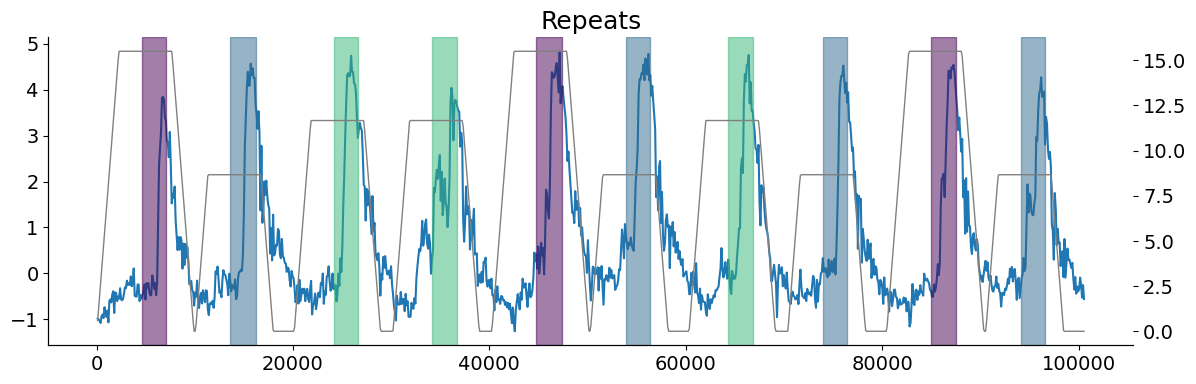

In [63]:
plt.figure(figsize=(14,4))
plt.title('Repeats')

repeats = np.arange(10)

repeat_start = trial_start_time[repeats[0]]*1000
repeat_end = trial_end_time[repeats[-1]]*1000

repeats_frames = (frames_time > repeat_start) & (frames_time < repeat_end)

ax = plt.gca()
ax1 = ax.twinx()
ax.plot(frames_time[repeats_frames], D.dFF[id, repeats_frames].T)
ax1.plot(frames_time[repeats_frames], stepper_pos_interp[repeats_frames]/30, lw=1, color='gray')

for rep in repeats:
    trial_start, trial_end = get_on_times(rep)
    plt.axvspan(trial_start, trial_end, color=colors[trial_sequence[rep]], alpha=0.5)


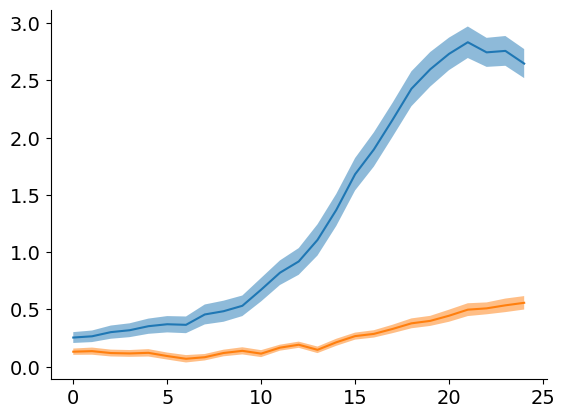

(60, 25)
(59, 25)


In [74]:
cell = 319
id = find_suite2p_cell(cell)

traces_all_mean, traces_all_sem = get_all_traces(id, mean_trace=True)
traces_one_mean, traces_one_sem = get_all_traces(id, mean_trace=True, block='one eye')
traces_two_mean, traces_two_sem = get_all_traces(id, mean_trace=True, block='two eyes')

plt.figure()
plt.plot(traces_one_mean.T)
# add sem as error bars
plt.fill_between(np.arange(len(traces_one_mean)), traces_one_mean - traces_one_sem, traces_one_mean + traces_one_sem, alpha=0.5)
plt.plot(traces_two_mean.T)
# add sem as error bars
plt.fill_between(np.arange(len(traces_two_mean)), traces_two_mean - traces_two_sem, traces_two_mean + traces_two_sem, alpha=0.5)
plt.show()

# find where is the max of traces_all_mean
max_all = np.argmax(traces_all_mean)



all_traces_one_distance = get_all_traces(id, block='one eye')




In [80]:
receptive_field_values = get_RF_value(id, block='one eye')

print(receptive_field_values)




[1.6758354, 0.13057587]
